# Amazon Product Data Analysis

This notebook uses a cleaned Amazon product CSV to answer eight questions with simple tables and charts.

Rating counts show review activity. They do not tell us how many products were sold.

## Step 1: Import the tools

Pandas reads the data and makes tables. Matplotlib makes charts.

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

## Step 2: Load the cleaned data

The product data was cleaned in `clean.ipynb`. We also load review text from the original CSV because it is not included in the cleaned file.

In [12]:
df = pd.read_csv("../Processed_Datasets/amazon_cleaned.csv")
review_text = pd.read_csv(
    "../Datasets/amazon.csv",
    usecols=["product_id", "review_title", "review_content"],
)
review_text = review_text.drop_duplicates("product_id")
df = df.merge(review_text, on="product_id", how="left")

print("Product listings:", len(df))
print("Products with review titles:", df["review_title"].notna().sum())
df.head()

Product listings: 1348
Products with review titles: 1348


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,main_category,review_title,review_content
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64,4.2,24269.0,High Compatibility : Compatible With iPhone 12...,Computers&Accessories,"Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43,4.0,43994.0,"Compatible with all Type C enabled devices, be...",Computers&Accessories,"A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90,3.9,7928.0,【 Fast Charger& Data Sync】-With built-in safet...,Computers&Accessories,"Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a..."
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53,4.2,94363.0,The boAt Deuce USB 300 2 in 1 cable is compati...,Computers&Accessories,"Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou..."
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61,4.2,16905.0,[CHARGE & SYNC FUNCTION]- This cable comes wit...,Computers&Accessories,"As good as original,Decent,Good one for second...","Bought this instead of original apple, does th..."


## Step 3: Check the dataset

Check the number of rows and columns, column types, and missing values.


In [13]:
print("Rows and columns:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())


Rows and columns: (1348, 12)

Column types:
product_id                 str
product_name               str
category                   str
discounted_price       float64
actual_price           float64
discount_percentage      int64
rating                 float64
rating_count           float64
about_product              str
main_category              str
review_title               str
review_content             str
dtype: object

Missing values:
product_id             0
product_name           0
category               0
discounted_price       0
actual_price           0
discount_percentage    0
rating                 0
rating_count           0
about_product          0
main_category          0
review_title           0
review_content         0
dtype: int64


## Question 1: What is the average rating for each product category?

We group the products by category and calculate the average rating. Some categories have very few products, so check the product counts too.

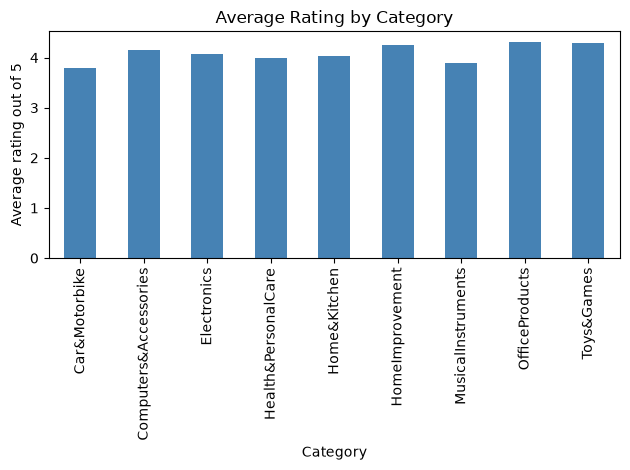

Average ratings:
main_category
Car&Motorbike            3.80
Computers&Accessories    4.15
Electronics              4.08
Health&PersonalCare      4.00
Home&Kitchen             4.04
HomeImprovement          4.25
MusicalInstruments       3.90
OfficeProducts           4.31
Toys&Games               4.30
Name: rating, dtype: float64
Product counts:
main_category
Electronics              490
Home&Kitchen             447
Computers&Accessories    373
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64


In [14]:
average_ratings = df.groupby("main_category")["rating"].mean()

average_ratings.plot(kind="bar", color="steelblue")
plt.title("Average Rating by Category")
plt.xlabel("Category")
plt.ylabel("Average rating out of 5")
plt.tight_layout()
plt.show()

print("Average ratings:")
print(average_ratings.round(2))
print("Product counts:")
print(df["main_category"].value_counts())

## Question 2: What are the top products by rating count in each category?

Here, we sort products by `rating_count` and show the top three in each category. Rating count is a review-activity measure, not confirmed sales.

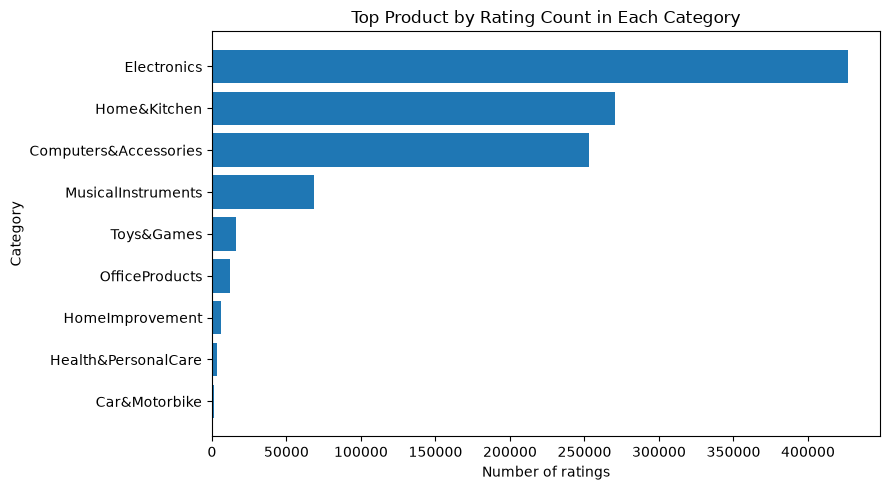

,main_category,product_name,rating,rating_count
65,Electronics,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...",4.4,426973.0
47,Electronics,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...",4.4,426973.0
12,Electronics,AmazonBasics Flexible Premium HDMI Cable (Blac...,4.4,426973.0
912,Home&Kitchen,Pigeon Polypropylene Mini Handy and Compact Ch...,4.1,270563.0
557,Computers&Accessories,SanDisk Cruzer Blade 32GB USB Flash Drive,4.3,253105.0
651,Computers&Accessories,SanDisk Ultra Dual 64 GB USB 3.0 OTG Pen Drive...,4.3,189104.0
143,Computers&Accessories,TP-Link Nano USB WiFi Dongle 150Mbps High Gain...,4.2,179692.0
906,Home&Kitchen,Pigeon by Stovekraft Amaze Plus Electric Kettl...,3.9,123365.0
574,MusicalInstruments,Boya ByM1 Auxiliary Omnidirectional Lavalier C...,4.0,68664.0
915,Home&Kitchen,"Prestige Electric Kettle PKOSS - 1500watts, St...",3.9,63350.0


In [15]:
sorted_products = df.sort_values("rating_count", ascending=False)
top_products_by_category = sorted_products.groupby("main_category").head(3)
top_products_by_category = top_products_by_category[
    ["main_category", "product_name", "rating", "rating_count"]
]

category_top_products = sorted_products.groupby("main_category").head(1)
category_top_products = category_top_products.sort_values("rating_count")
plt.figure(figsize=(9, 5))
plt.barh(category_top_products["main_category"], category_top_products["rating_count"])
plt.title("Top Product by Rating Count in Each Category")
plt.xlabel("Number of ratings")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

top_products_by_category

## Question 3: How are discounted prices different from actual prices?

This chart puts both price columns on the same graph. A few very expensive products stretch the horizontal scale, so most products appear on the left.

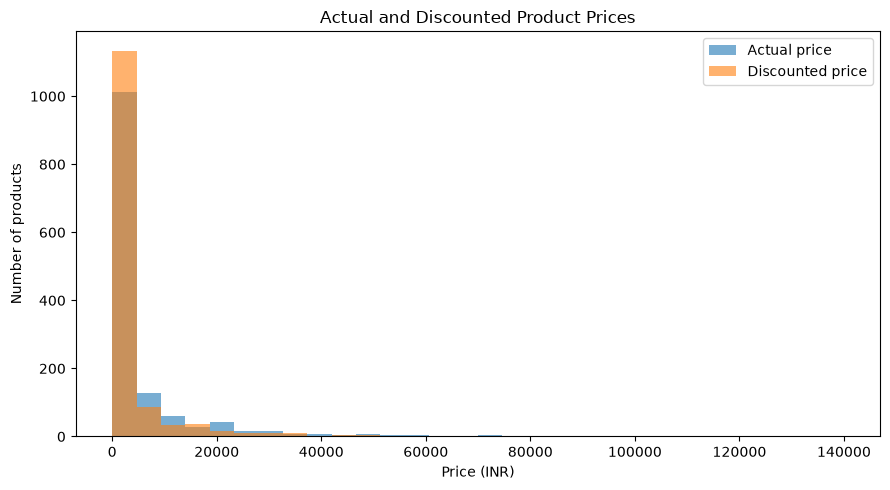

Median actual price: 1795.0
Median discounted price: 899.0
Takeaway: the typical discounted price is lower than the typical actual price.


In [16]:
maximum_price = max(df["actual_price"].max(), df["discounted_price"].max())

plt.figure(figsize=(9, 5))
plt.hist(df["actual_price"], bins=30, range=(0, maximum_price), alpha=0.6, label="Actual price")
plt.hist(df["discounted_price"], bins=30, range=(0, maximum_price), alpha=0.6, label="Discounted price")
plt.title("Actual and Discounted Product Prices")
plt.xlabel("Price (INR)")
plt.ylabel("Number of products")
plt.legend()
plt.tight_layout()
plt.show()

print("Median actual price:", round(df["actual_price"].median(), 2))
print("Median discounted price:", round(df["discounted_price"].median(), 2))
print("Takeaway: the typical discounted price is lower than the typical actual price.")

## Question 4: How does the average discount percentage vary by category?

We find the average discount for each category and draw a bar chart. We also print the number of products in each category.

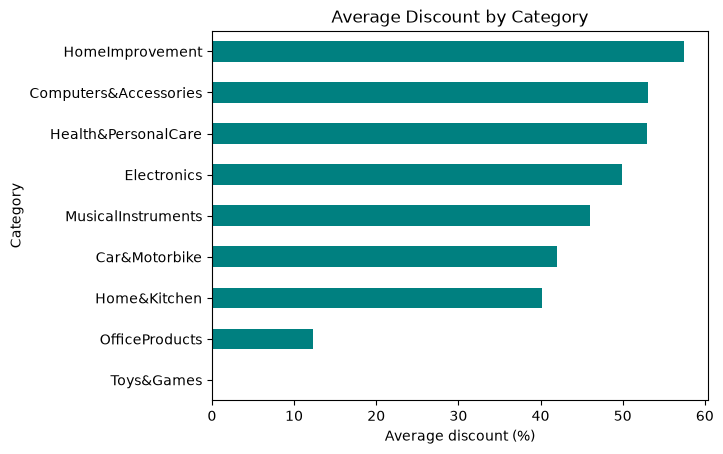

Average discount by category:
main_category
Toys&Games                0.0
OfficeProducts           12.4
Home&Kitchen             40.2
Car&Motorbike            42.0
MusicalInstruments       46.0
Electronics              49.9
Health&PersonalCare      53.0
Computers&Accessories    53.1
HomeImprovement          57.5
Name: discount_percentage, dtype: float64
Product counts:
main_category
Electronics              490
Home&Kitchen             447
Computers&Accessories    373
OfficeProducts            31
MusicalInstruments         2
HomeImprovement            2
Toys&Games                 1
Car&Motorbike              1
Health&PersonalCare        1
Name: count, dtype: int64


In [17]:
average_discounts = df.groupby("main_category")["discount_percentage"].mean()
average_discounts = average_discounts.sort_values()

average_discounts.plot(kind="barh", color="teal")
plt.title("Average Discount by Category")
plt.xlabel("Average discount (%)")
plt.ylabel("Category")
plt.show()

print("Average discount by category:")
print(average_discounts.round(1))
print("Product counts:")
print(df["main_category"].value_counts())

## Question 5: What are the most popular product names?

We use the number of ratings as a simple popularity proxy and plot the ten products with the most ratings. This does not tell us how many units were sold.

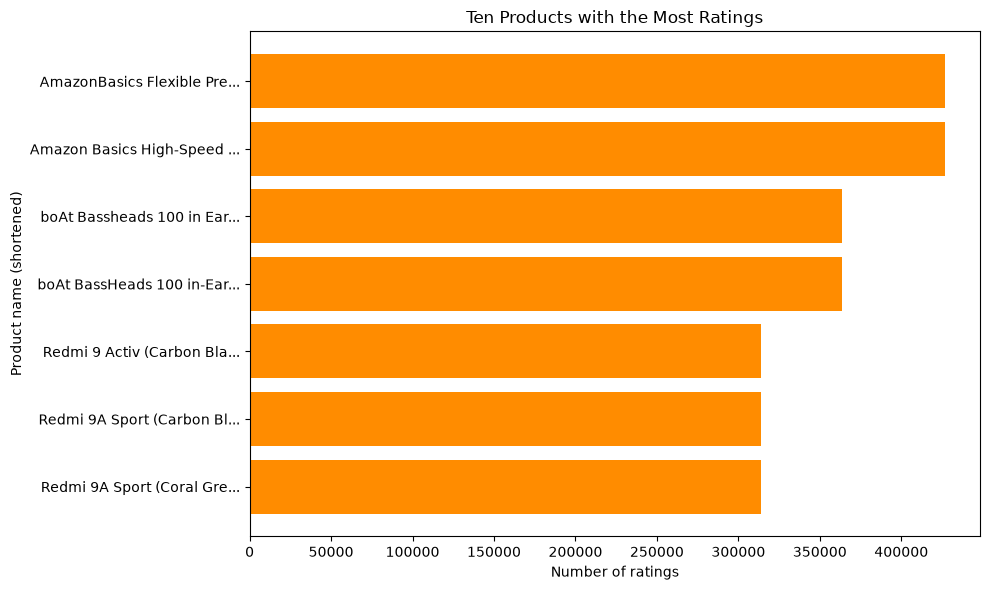

Most-rated product: AmazonBasics Flexible Premium HDMI Cable (Black, 4K@60Hz, 18Gbps), 3-Foot
Number of ratings: 426973
Rating count is a sign of review activity, not the number of products sold.


In [18]:
top_ten_products = df.sort_values("rating_count", ascending=False).head(10)
top_ten_products = top_ten_products.sort_values("rating_count")
short_names = top_ten_products["product_name"].str.slice(0, 25) + "..."

plt.figure(figsize=(10, 6))
plt.barh(short_names, top_ten_products["rating_count"], color="darkorange")
plt.title("Ten Products with the Most Ratings")
plt.xlabel("Number of ratings")
plt.ylabel("Product name (shortened)")
plt.tight_layout()
plt.show()

print("Most-rated product:", top_ten_products.iloc[-1]["product_name"])
print("Number of ratings:", int(top_ten_products.iloc[-1]["rating_count"]))
print("Rating count is a sign of review activity, not the number of products sold.")

## Question 6: What do reviews for the most-rated products say?

We sort products by rating count and look at a short sample of each product's review titles. The source combines multiple review titles in one cell.

In [19]:
top_review_products = df.sort_values("rating_count", ascending=False).head(5)
top_review_products = top_review_products[
    ["product_name", "rating_count", "review_title"]
]
top_review_products["review_title"] = top_review_products["review_title"].str.slice(0, 100)
top_review_products

,product_name,rating_count,review_title
65,"Amazon Basics High-Speed HDMI Cable, 6 Feet (2...",426973.0,"It's quite good and value for money,Works well..."
47,"Amazon Basics High-Speed HDMI Cable, 6 Feet - ...",426973.0,"It's quite good and value for money,Works well..."
12,AmazonBasics Flexible Premium HDMI Cable (Blac...,426973.0,"It's quite good and value for money,Works well..."
393,boAt Bassheads 100 in Ear Wired Earphones with...,363713.0,"Best value for money,HEAD PHONE POUCH NOT RECE..."
350,boAt Bassheads 100 in Ear Wired Earphones with...,363713.0,"Best value for money,HEAD PHONE POUCH NOT RECE..."
